# Parte Comum — K-Means e Métricas (Obesity)

Fluxo:
1. Padronização das variáveis numéricas
2. **Passada 1** — k livre, escolhido pelo Método do Cotovelo
3. **Passada 2** — k fixo = número de classes reais (7)
4. Para cada passada: mapeamento cluster → classe majoritária, matriz de confusão, acurácia, precisão e recall
5. Comparação entre as passadas

As funções estão em `src/parte_comum/kmeans.py`.

In [1]:
# [IA] Claude – configuração do notebook e imports
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1] if Path.cwd().name == "parte_comum" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.parte_comum import kmeans as km

OUT = RAIZ / "out" / "parte_comum"
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# [IA] Claude – carregamento dos dados
df = km.carregar_dados()
print(df.shape)
print("Número de classes reais:", df[km.ALVO].nunique())
df.head()

(2111, 17)
Número de classes reais: 7


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1. Variáveis e padronização

O grupo escolhe o conjunto de variáveis em `CONJUNTO`:

- `"numericas"`: as 8 variáveis numéricas
- `"todas"`: numéricas + binárias em 0/1 + `CAEC` e `CALC` em 0 a 3 + one-hot de `MTRANS`

Depois, cada coluna recebe z-score: $z = (x - \mu) / \sigma$. A classe real nunca entra no agrupamento.

> ✍️ **Análise do grupo:** _(preencher)_

_Por que a padronização é necessária antes do K-Means?_

In [3]:
# [IA] Claude – escolha das variáveis, padronização e comparação antes/depois
CONJUNTO = "numericas"  # "numericas" ou "todas": o grupo decide e justifica no relatório

X_original = km.codificar(df, CONJUNTO)
X, scaler = km.preparar_X(df, CONJUNTO)
print(f"{km.CONJUNTOS[CONJUNTO]}: {X.shape[1]} colunas de entrada")

comparacao = pd.concat(
    {
        "média (original)": X_original.mean(),
        "desvio (original)": X_original.std(),
        "média (padronizada)": X.mean(),
        "desvio (padronizada)": X.std(),
    },
    axis=1,
)
comparacao

Só as 8 variáveis numéricas: 8 colunas de entrada


,média (original),desvio (original),média (padronizada),desvio (padronizada)
Age,24.313,6.346,0.000e+00,1.0
Height,1.702,0.093,-5.385e-16,1.0
Weight,86.586,26.191,-5.385e-16,1.0
FCVC,2.419,0.534,-1.346e-17,1.0
NCP,2.686,0.778,4.965e-16,1.0
CH2O,2.008,0.613,1.077e-16,1.0
FAF,1.010,0.851,2.693e-17,1.0
TUE,0.658,0.609,-1.346e-17,1.0


In [4]:
# [IA] Claude – funções auxiliares de visualização
PALETA = sns.color_palette("tab10")

def plot_clusters_pca(clusters, titulo, arquivo):
    proj, var = km.projetar_pca(X)
    proj["cluster"] = clusters
    proj["classe_real"] = pd.Categorical(df[km.ALVO], categories=km.ORDEM_CLASSES)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
    sns.scatterplot(data=proj, x="PC1", y="PC2", hue="cluster", palette="tab10",
                    s=18, alpha=0.7, ax=axes[0])
    axes[0].set_title("Clusters do K-Means")
    sns.scatterplot(data=proj, x="PC1", y="PC2", hue="classe_real", palette="viridis",
                    s=18, alpha=0.7, ax=axes[1])
    axes[1].set_title("Classes reais (NObeyesdad)")
    for ax in axes:
        ax.set_xlabel(f"PC1 ({var[0]:.1%} da variância)")
        ax.set_ylabel(f"PC2 ({var[1]:.1%} da variância)")
        ax.legend(title=ax.get_legend().get_title().get_text(), fontsize=8,
                  title_fontsize=9, loc="best")
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT / arquivo, dpi=150, bbox_inches="tight")
    plt.show()


def plot_heatmap(tabela, titulo, xlabel, ylabel, arquivo, fmt="d"):
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(tabela) + 2))
    sns.heatmap(tabela, annot=True, fmt=fmt, cmap="Blues", cbar_kws={"label": "Nº de pessoas"}, ax=ax)
    ax.set_title(titulo, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    fig.tight_layout()
    fig.savefig(OUT / arquivo, dpi=150, bbox_inches="tight")
    plt.show()


def mostrar_passada(res, nome):
    print(f"{nome} — k = {res['k']}")
    print("Mapeamento cluster → classe majoritária:")
    for c, classe in sorted(res["mapa"].items()):
        print(f"  cluster {c}: {classe}")
    print(f"\nAcurácia: {res['acuracia']:.3f}")
    return res["por_classe"]

## 2. Passada 1 — k livre (Método do Cotovelo)

K-Means com k de 2 a 10, registrando a inércia (soma das distâncias quadradas de cada ponto ao centróide do seu cluster).

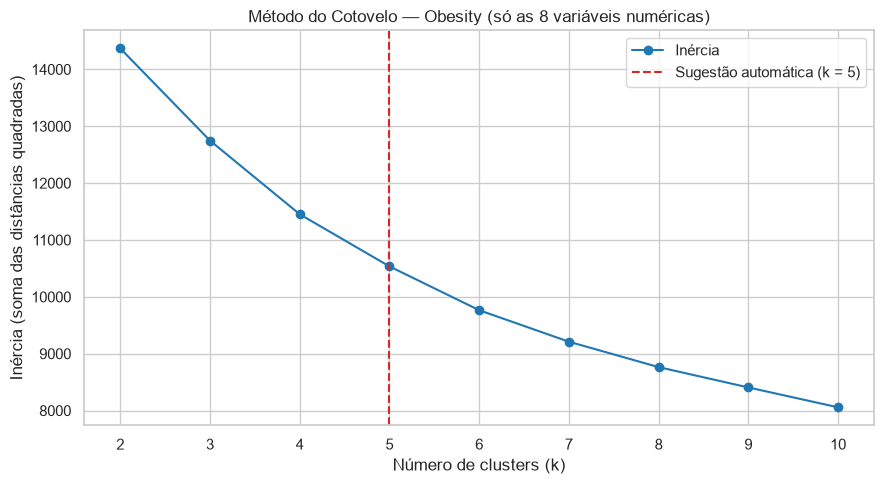

,k,inercia,queda_pct
0,2,14367.974,NaN
1,3,12746.691,11.3
2,4,11451.560,10.2
3,5,10534.863,8.0
4,6,9764.333,7.3
5,7,9210.443,5.7
6,8,8763.675,4.9
7,9,8405.990,4.1
8,10,8056.622,4.2


In [5]:
# [IA] Claude – curva do cotovelo
curva = km.curva_cotovelo(X, ks=range(2, 11))
k_sugerido = km.sugerir_k_cotovelo(curva)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curva["k"], curva["inercia"], marker="o", color="tab:blue", label="Inércia")
ax.axvline(k_sugerido, color="tab:red", linestyle="--",
           label=f"Sugestão automática (k = {k_sugerido})")
ax.set_title(f"Método do Cotovelo — Obesity ({km.CONJUNTOS[CONJUNTO].lower()})")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia (soma das distâncias quadradas)")
ax.set_xticks(curva["k"])
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "cotovelo.png", dpi=150, bbox_inches="tight")
plt.show()

curva.assign(queda_pct=(-curva["inercia"].pct_change() * 100).round(1))

A linha vermelha é só uma referência numérica (ponto da curva mais distante da reta entre k=2 e k=10).
**A escolha do k é do grupo**: altere `K_LIVRE` na célula abaixo se decidirem outro valor.

> ✍️ **Análise do grupo:** _(preencher)_

_Qual k foi escolhido e por quê?_

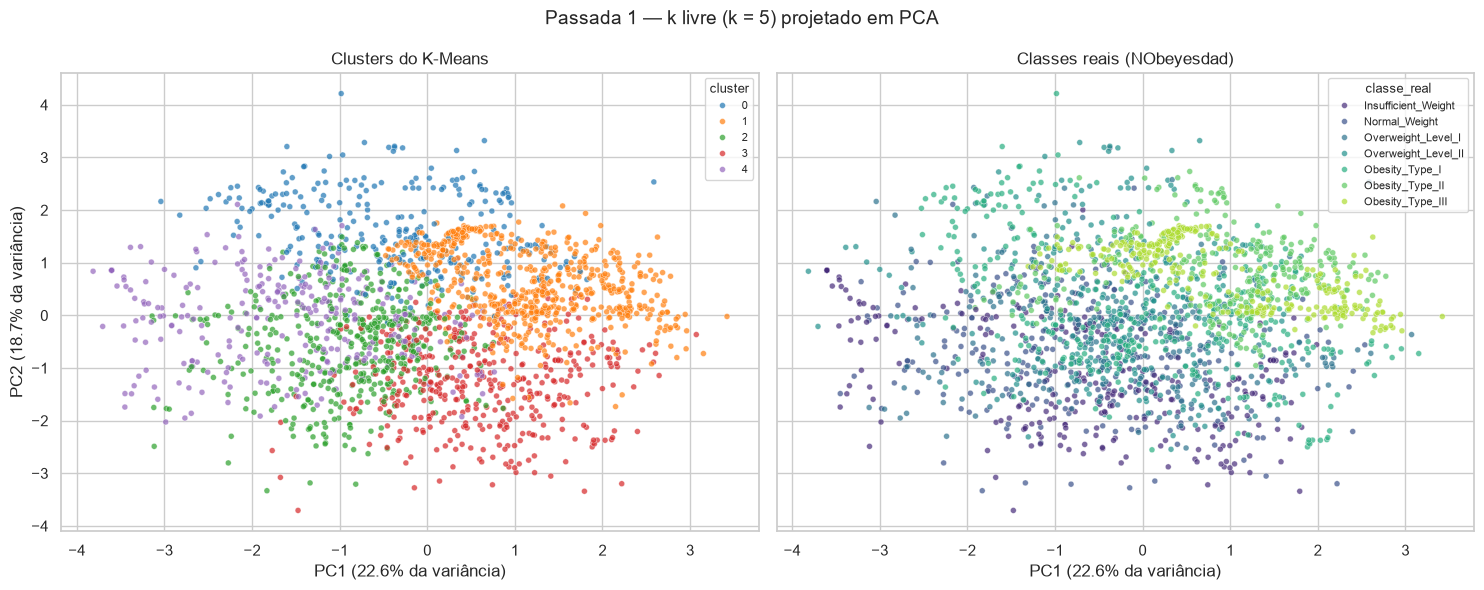

In [6]:
K_LIVRE = k_sugerido  # o grupo pode substituir por outro valor após analisar a curva

res_livre = km.avaliar_passada(df, X, K_LIVRE)
plot_clusters_pca(res_livre["clusters"], f"Passada 1 — k livre (k = {K_LIVRE}) projetado em PCA",
                  "passada1_pca.png")

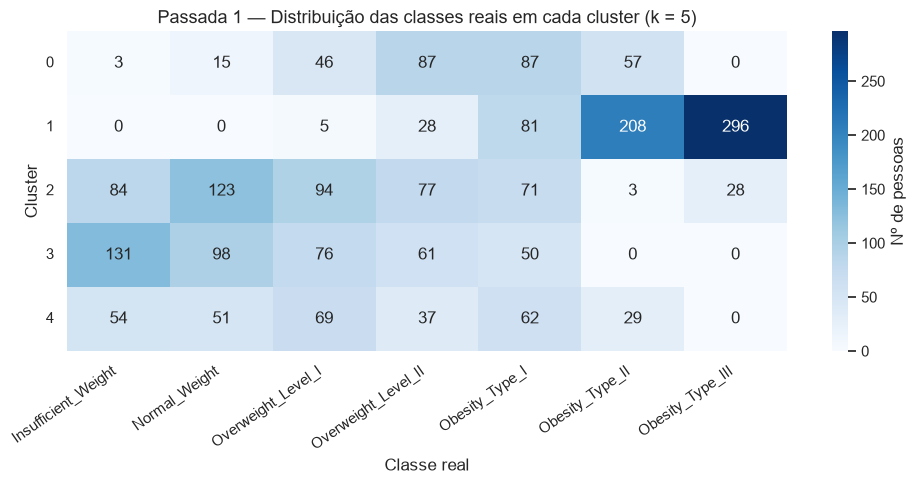

In [7]:
plot_heatmap(res_livre["contingencia"],
             f"Passada 1 — Distribuição das classes reais em cada cluster (k = {K_LIVRE})",
             "Classe real", "Cluster", "passada1_contingencia.png")

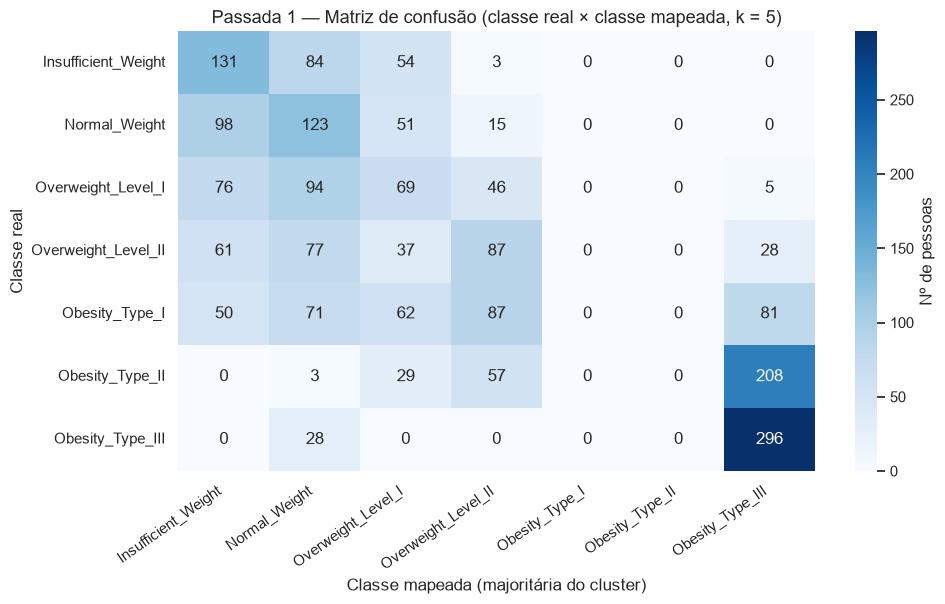

In [8]:
plot_heatmap(res_livre["matriz"],
             f"Passada 1 — Matriz de confusão (classe real × classe mapeada, k = {K_LIVRE})",
             "Classe mapeada (majoritária do cluster)", "Classe real", "passada1_matriz_confusao.png")

In [9]:
mostrar_passada(res_livre, "Passada 1")

Passada 1 — k = 5
Mapeamento cluster → classe majoritária:
  cluster 0: Overweight_Level_II
  cluster 1: Obesity_Type_III
  cluster 2: Normal_Weight
  cluster 3: Insufficient_Weight
  cluster 4: Overweight_Level_I

Acurácia: 0.334


,precisao,recall,suporte
real,,,
Insufficient_Weight,0.315,0.482,272
Normal_Weight,0.256,0.429,287
Overweight_Level_I,0.228,0.238,290
Overweight_Level_II,0.295,0.300,290
Obesity_Type_I,NaN,0.000,351
Obesity_Type_II,NaN,0.000,297
Obesity_Type_III,0.479,0.914,324


> ✍️ **Análise do grupo:** _(preencher)_

_Interpretação da Passada 1._

## 3. Passada 2 — k fixo (número real de classes)

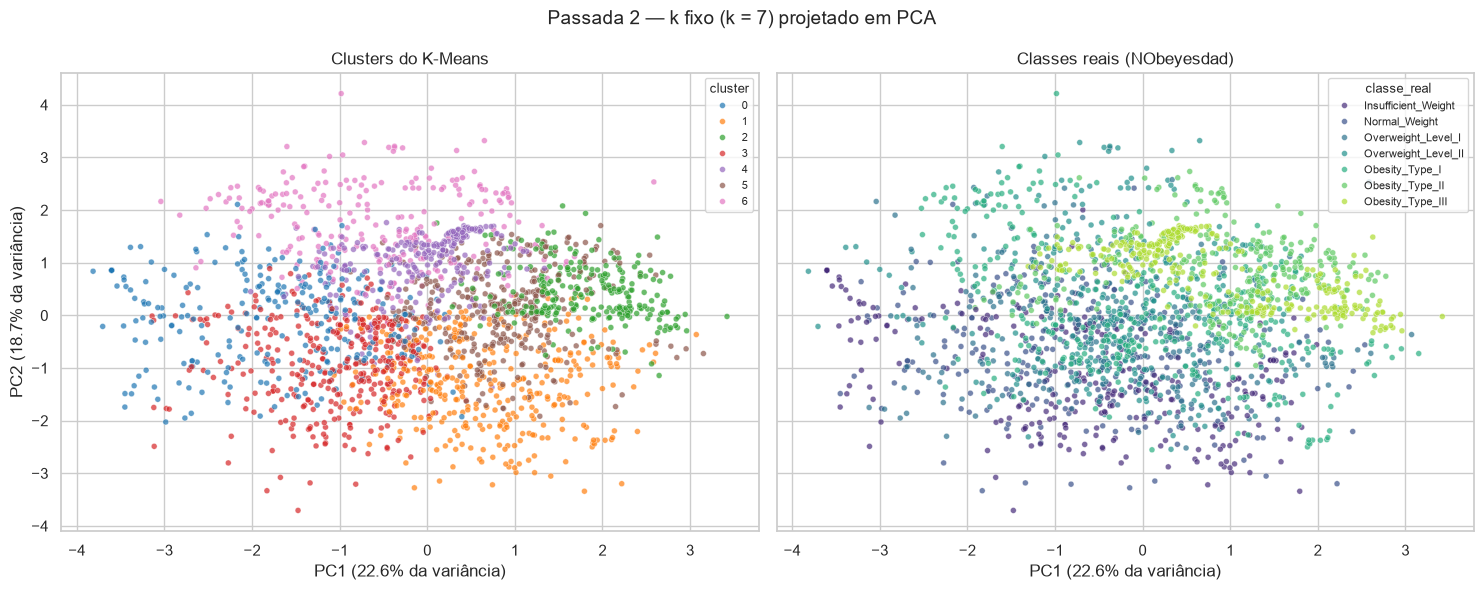

In [10]:
K_FIXO = df[km.ALVO].nunique()

res_fixo = km.avaliar_passada(df, X, K_FIXO)
plot_clusters_pca(res_fixo["clusters"], f"Passada 2 — k fixo (k = {K_FIXO}) projetado em PCA",
                  "passada2_pca.png")

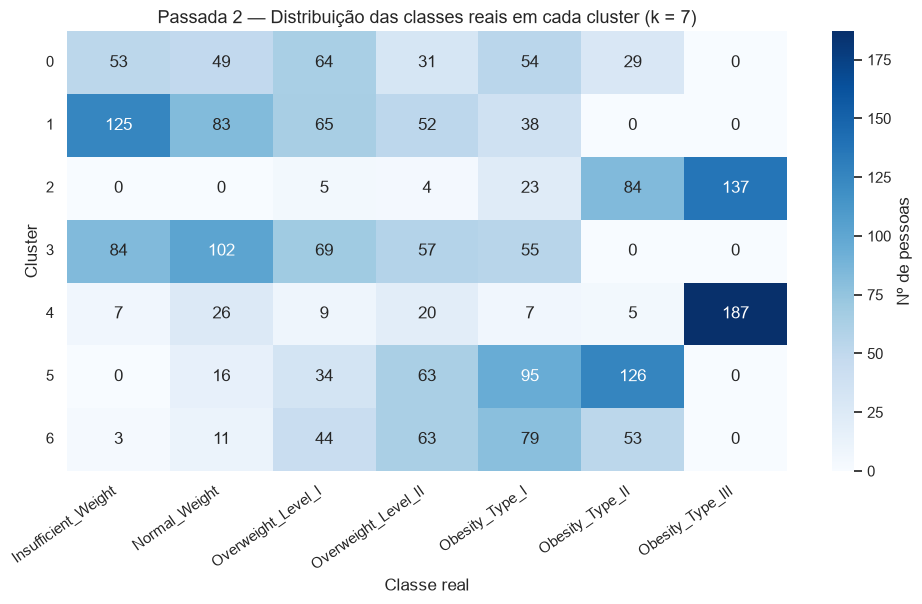

In [11]:
plot_heatmap(res_fixo["contingencia"],
             f"Passada 2 — Distribuição das classes reais em cada cluster (k = {K_FIXO})",
             "Classe real", "Cluster", "passada2_contingencia.png")

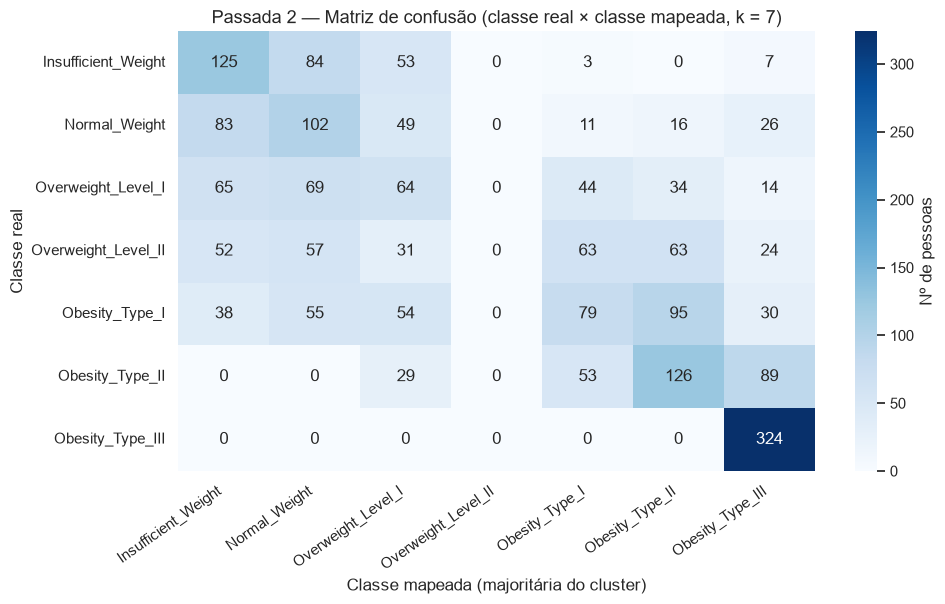

In [12]:
plot_heatmap(res_fixo["matriz"],
             f"Passada 2 — Matriz de confusão (classe real × classe mapeada, k = {K_FIXO})",
             "Classe mapeada (majoritária do cluster)", "Classe real", "passada2_matriz_confusao.png")

In [13]:
mostrar_passada(res_fixo, "Passada 2")

Passada 2 — k = 7
Mapeamento cluster → classe majoritária:
  cluster 0: Overweight_Level_I
  cluster 1: Insufficient_Weight
  cluster 2: Obesity_Type_III
  cluster 3: Normal_Weight
  cluster 4: Obesity_Type_III
  cluster 5: Obesity_Type_II
  cluster 6: Obesity_Type_I

Acurácia: 0.388


,precisao,recall,suporte
real,,,
Insufficient_Weight,0.344,0.460,272
Normal_Weight,0.278,0.355,287
Overweight_Level_I,0.229,0.221,290
Overweight_Level_II,NaN,0.000,290
Obesity_Type_I,0.312,0.225,351
Obesity_Type_II,0.377,0.424,297
Obesity_Type_III,0.630,1.000,324


> ✍️ **Análise do grupo:** _(preencher)_

_Interpretação da Passada 2._

## 4. Comparação entre as passadas

In [14]:
# [IA] Claude – tabela comparativa e exportação das métricas
comparativo = pd.concat(
    {f"Passada 1 (k={K_LIVRE})": res_livre["por_classe"][["precisao", "recall"]],
     f"Passada 2 (k={K_FIXO})": res_fixo["por_classe"][["precisao", "recall"]]},
    axis=1,
)
print(f"Acurácia — Passada 1: {res_livre['acuracia']:.3f} | Passada 2: {res_fixo['acuracia']:.3f}")

for nome, res in [("passada1", res_livre), ("passada2", res_fixo)]:
    res["contingencia"].to_csv(OUT / f"{nome}_contingencia.csv")
    res["matriz"].to_csv(OUT / f"{nome}_matriz_confusao.csv")
    res["por_classe"].to_csv(OUT / f"{nome}_metricas_por_classe.csv")
curva.to_csv(OUT / "cotovelo.csv", index=False)

comparativo

Acurácia — Passada 1: 0.334 | Passada 2: 0.388


Passada 1 (k=5)        Passada 2 (k=7)       
                           precisao recall        precisao recall
real                                                             
Insufficient_Weight           0.315  0.482           0.344  0.460
Normal_Weight                 0.256  0.429           0.278  0.355
Overweight_Level_I            0.228  0.238           0.229  0.221
Overweight_Level_II           0.295  0.300             NaN  0.000
Obesity_Type_I                  NaN  0.000           0.312  0.225
Obesity_Type_II                 NaN  0.000           0.377  0.424
Obesity_Type_III              0.479  0.914           0.630  1.000

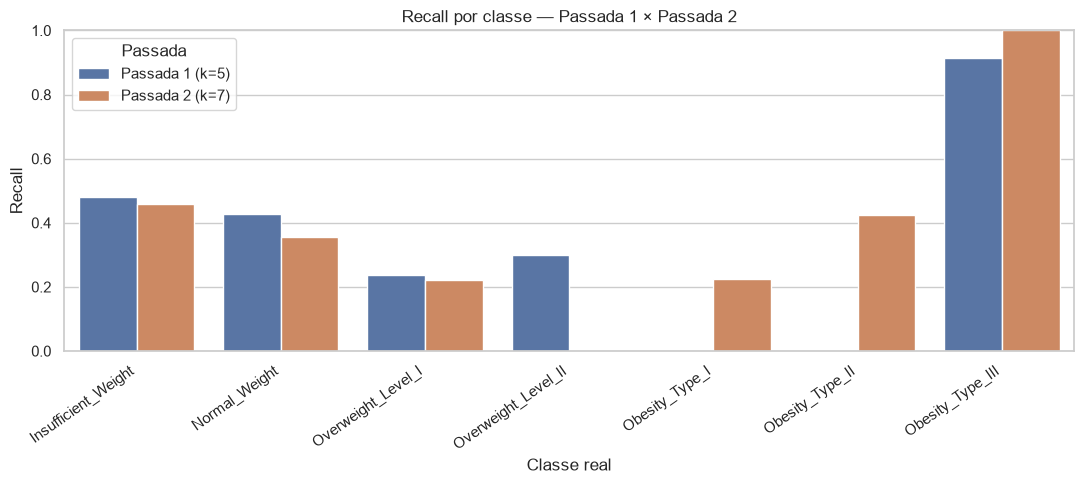

In [15]:
# [IA] Claude – recall por classe nas duas passadas
recall_long = (
    comparativo.xs("recall", axis=1, level=1)
    .reset_index()
    .melt(id_vars="real", var_name="passada", value_name="recall")
)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=recall_long, x="real", y="recall", hue="passada", ax=ax)
ax.set_title("Recall por classe — Passada 1 × Passada 2")
ax.set_xlabel("Classe real")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.legend(title="Passada")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(OUT / "comparacao_recall.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# [IA] Claude – conferência dos cálculos manuais com o scikit-learn
from sklearn.metrics import accuracy_score, precision_score, recall_score

for nome, res in [("Passada 1", res_livre), ("Passada 2", res_fixo)]:
    y_real = df[km.ALVO]
    y_map = pd.Series(res["clusters"]).map(res["mapa"])
    ok_acc = np.isclose(accuracy_score(y_real, y_map), res["acuracia"])
    rec = recall_score(y_real, y_map, labels=km.ORDEM_CLASSES, average=None, zero_division=np.nan)
    pre = precision_score(y_real, y_map, labels=km.ORDEM_CLASSES, average=None, zero_division=np.nan)
    ok_rec = np.allclose(rec, res["por_classe"]["recall"], equal_nan=True)
    ok_pre = np.allclose(pre, res["por_classe"]["precisao"], equal_nan=True)
    print(f"{nome}: acurácia {ok_acc} | precisão {ok_pre} | recall {ok_rec}")

Passada 1: acurácia True | precisão True | recall True
Passada 2: acurácia True | precisão True | recall True


### 4.1 Comparação dos conjuntos de variáveis

Roda as duas passadas com cada conjunto. O k livre aqui é sempre a sugestão automática do cotovelo.

In [17]:
# [IA] Claude – comparação entre os conjuntos de variáveis
linhas = []
for nome, descricao in km.CONJUNTOS.items():
    X_c, _ = km.preparar_X(df, nome)
    k_c = km.sugerir_k_cotovelo(km.curva_cotovelo(X_c))
    livre, fixo = km.avaliar_passada(df, X_c, k_c), km.avaliar_passada(df, X_c, K_FIXO)
    linhas.append({
        "conjunto": descricao,
        "colunas": X_c.shape[1],
        "k sugerido": k_c,
        "acurácia (k sugerido)": livre["acuracia"],
        "classes sem cluster (k sugerido)": int(livre["por_classe"]["precisao"].isna().sum()),
        "acurácia (k = 7)": fixo["acuracia"],
        "classes sem cluster (k = 7)": int(fixo["por_classe"]["precisao"].isna().sum()),
    })
comparacao_conjuntos = pd.DataFrame(linhas).set_index("conjunto")
comparacao_conjuntos.to_csv(OUT / "comparacao_conjuntos.csv")
comparacao_conjuntos

,colunas,k sugerido,acurácia (k sugerido),classes sem cluster (k sugerido),acurácia (k = 7),classes sem cluster (k = 7)
conjunto,,,,,,
Só as 8 variáveis numéricas,8,5,0.334,2,0.388,1
Numéricas + categóricas codificadas,20,6,0.400,2,0.387,2


> ✍️ **Análise do grupo:** _(preencher)_

_Qual conjunto de variáveis foi escolhido e por quê?_

## 5. Discussão crítica

> ✍️ **Análise do grupo:** _(preencher)_

- _Qual passada gerou grupos mais coerentes?_
- _A granularidade das 7 classes faz sentido do ponto de vista dos dados?_